# Does the BVOC emissions response to forest expansion change between PD and FUT?

Standalone analysis of SFISOP and SFMTERP in CTRL_PD, LCC_PD, CTRL_FUT and LCC_FUT, using monthly means for 2001–2009.

**Expansion PD = LCC_PD − CTRL_PD**  
**Expansion FUT = LCC_FUT − CTRL_FUT**  
**Interaction = Expansion FUT − Expansion PD**

Reports annual budgets, seasonal cycles, spatial cancellation, the two attribution sequences, and annual/JJA maps. Regions: modified cells ≥45°N, unmodified cells ≥45°N, and all cells ≥45°N.

Annual variability is descriptive, not a formal significance test.

In [1]:
from pathlib import Path
from glob import glob
import calendar
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from IPython.display import display

FILES = {
    "CTRL_PD": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925/atm/hist/*.cam.h0.*.nc",
    "CTRL_FUT": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925/atm/hist/*.cam.h0.*.nc",
    "LCC_FUT": "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005/atm/hist/*.cam.h0.*.nc",
}
START_YEAR, END_YEAR = 2001, 2009
MIN_LAT = 45
VARS = ["SFISOP", "SFMTERP"]
LABELS = {"SFISOP": "Isoprene", "SFMTERP": "Monoterpenes"}
COLORS = {"Background": "#4477AA", "Expansion": "#228833", "Total": "#333333"}
OUT = Path("bvoc_expansion_PD_FUT_interaction_outputs")
OUT.mkdir(exist_ok=True)

# Set True only for processed files whose timestamps identify the represented month.
# Raw CAM next-month timestamps require time bounds.
TRUST_TIMESTAMPS_WITHOUT_BOUNDS = False
AREA_FILE = None  # Optional NetCDF with cell area on the same lat/lon grid.
AREA_VAR, AREA_UNITS = "area", "m2"  # Alternatives: km2, sr
EARTH_RADIUS = 6_371_000
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc")
MASK_VAR = None  # e.g. "modified_cells"; auto-detect only a unique binary 2D candidate.
MASK_NAN_IS_FALSE = False  # Set True only if missing values explicitly mean unmodified.

FILES["LCC_PD"] = "/cluster/home/adelez/BRL-FRST-XPSN_archive/NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005/atm/hist/*.cam.h0.*.nc"
RUN_MAPS = True  # Set False to skip to produce annual and JJA polar maps.
MAP_QUANTILE = 1.0  # 1.0 = full range; e.g. 0.98 to reveal weaker patterns.
if not 0 < MAP_QUANTILE <= 1:
    raise ValueError("MAP_QUANTILE must be in (0, 1].")


## 1. Read monthly emissions once
Uses time bounds to identify complete calendar months and retains only SFISOP/SFMTERP. Re-running later plotting cells does not reload simulation files.

In [2]:
missing = [case for case, path in FILES.items() if not path]
if missing:
    raise ValueError(f"Set the input file pattern for: {missing}")

def seconds_between(start, end):
    delta = end - start
    return float(delta / np.timedelta64(1, "s")) if isinstance(delta, np.timedelta64) else delta.total_seconds()

def date_parts(value):
    if isinstance(value, np.datetime64):
        value = pd.Timestamp(value)
    return value.year, value.month, value.day, value.hour, value.minute, value.second

def read_case(pattern):
    paths = sorted(glob(str(Path(pattern).expanduser())))
    if not paths:
        raise FileNotFoundError(pattern)
    chunks, records = [], []
    for path in paths:
        with xr.open_dataset(path) as ds:
            bounds_name = ds.time.attrs.get("bounds")
            if not bounds_name or bounds_name not in ds:
                bounds_name = next((v for v in ("time_bnds", "time_bounds") if v in ds), None)
            selected, keys, durations = [], [], []
            for i, stamp in enumerate(ds.time.values):
                if bounds_name:
                    start, end = ds[bounds_name].isel(time=i).values.ravel()
                    midpoint = start + (end - start) / 2
                    year, month, *_ = date_parts(midpoint)
                    duration = seconds_between(start, end)
                    sy, sm, sd, sh, smin, ss = date_parts(start)
                    ey, em, ed, eh, emin, es = date_parts(end)
                    next_month = (sy + (sm == 12), sm % 12 + 1)
                    monthly = (sd == ed == 1 and (ey, em) == next_month
                               and (sy, sm) == (year, month) and 27 <= duration / 86400 <= 31
                               and sh == smin == ss == eh == emin == es == 0)
                else:
                    if not TRUST_TIMESTAMPS_WITHOUT_BOUNDS:
                        raise ValueError(f"{path}: no time bounds; confirm timestamp convention in configuration.")
                    year, month, *_ = date_parts(stamp)
                    duration = float(ds.time.dt.days_in_month.isel(time=i)) * 86400
                    monthly = True
                if not START_YEAR <= year <= END_YEAR:
                    continue
                if not monthly:
                    raise ValueError(f"{path}: record {i} is not a complete calendar month.")
                selected.append(i)
                keys.append(year * 100 + month)
                durations.append(duration)
            if not selected:
                continue
            for var in VARS:
                if set(ds[var].dims) != {"time", "lat", "lon"}:
                    raise ValueError(f"{path}: unexpected dimensions for {var}: {ds[var].dims}")
                unit = ds[var].attrs.get("units", "").lower().replace(" ", "").replace("**", "^")
                if unit not in {"kg/m2/s", "kg/m^2/s", "kgm-2s-1", "kgm^-2s^-1"}:
                    raise ValueError(f"{path}: verify units for {var}: {ds[var].attrs.get('units')}")
            chunk = ds[VARS].isel(time=selected).assign_coords(time=keys).load()
            chunk["seconds"] = ("time", durations)
            chunks.append(chunk)
            records.extend(keys)
    expected = [y * 100 + m for y in range(START_YEAR, END_YEAR + 1) for m in range(1, 13)]
    if sorted(records) != expected:
        raise ValueError("Expected exactly one record per month; check gaps, duplicates and selected years.")
    result = xr.concat(chunks, dim="time", join="exact").sortby("time").sortby("lat").sortby("lon")
    result = result.assign_coords(year=("time", result.time.values // 100),
                                  month=("time", result.time.values % 100))
    if not bool(np.isfinite(result[VARS].to_array()).all()):
        raise ValueError("Missing/nonfinite emissions: inspect before spatial integration.")
    print(f"{len(paths)} files inspected; {result.sizes['time']} monthly records loaded.")
    return result

cases = {alias: read_case(pattern) for alias, pattern in FILES.items()}
cases = dict(zip(cases, xr.align(*cases.values(), join="exact")))
reference = cases["CTRL_PD"]
for alias, ds in cases.items():
    np.testing.assert_allclose(ds.seconds, reference.seconds, rtol=0, atol=0)

120 files inspected; 108 monthly records loaded.
120 files inspected; 108 monthly records loaded.
120 files inspected; 108 monthly records loaded.
120 files inspected; 108 monthly records loaded.


## 2. Cell area
Fluxes are grid-box-area fluxes in kg m⁻² s⁻¹. Integrate over whole grid-cell area; do not multiply by land fraction or changed-PFT fraction again. A modified grid cell may contain both changed and unchanged vegetation.

The default area estimate applies only to a regular global latitude–longitude grid. A supplied model area field is preferable when available.

In [3]:
def grid_area(ds):
    lat, lon = ds.lat.values, ds.lon.values
    if len(lat) < 2 or len(lon) < 2:
        raise ValueError("Need a full grid or an explicit area file.")
    dlat, dlon = np.diff(lat), np.diff(lon)
    if not (np.allclose(dlat, dlat[0]) and np.allclose(dlon, dlon[0])):
        raise ValueError("Nonuniform grid: provide AREA_FILE.")
    if not np.isclose(dlon[0] * len(lon), 360):
        raise ValueError("Expected global longitude coverage; provide AREA_FILE.")
    if lat[0] - dlat[0] / 2 > -89.99 or lat[-1] + dlat[0] / 2 < 89.99:
        raise ValueError("Expected global latitude coverage; provide AREA_FILE.")
    edges = np.r_[-90, (lat[:-1] + lat[1:]) / 2, 90]
    bands = EARTH_RADIUS**2 * np.diff(np.sin(np.deg2rad(edges))) * np.deg2rad(dlon[0])
    return xr.DataArray(np.broadcast_to(bands[:, None], (len(lat), len(lon))),
                        dims=("lat", "lon"), coords={"lat": ds.lat, "lon": ds.lon})

if AREA_FILE:
    with xr.open_dataset(Path(AREA_FILE).expanduser()) as ds:
        area = ds[AREA_VAR].load().squeeze(drop=True).sortby("lat").sortby("lon")
    area = area * {"m2": 1, "km2": 1e6, "sr": EARTH_RADIUS**2}[AREA_UNITS]
    area, _ = xr.align(area, reference.SFISOP.isel(time=0, drop=True), join="exact")
else:
    area = grid_area(reference)
if set(area.dims) != {"lat", "lon"} or not bool((np.isfinite(area) & (area > 0)).all()):
    raise ValueError("Area must be finite, positive and two-dimensional.")



## 3. Inspect the mask and define the three regions
Only binary 0/1 masks are accepted. Extra singleton dimensions are removed, but time-dependent or PFT-dependent masks are not silently collapsed.

Longitude conventions are normalized before matching. Cell coordinates must then match the CAM grid within 0.00001°; no interpolation or nearest-neighbour remapping is performed. Missing mask values require an explicit choice.

In [4]:
with xr.open_dataset(MASK_FILE) as mask_ds:
    display(pd.DataFrame([{"variable": name, "dimensions": str(v.dims), "shape": str(v.shape),
                           "description": v.attrs.get("long_name", "")}
                          for name, v in mask_ds.data_vars.items()]))

    candidates = []
    for name, v in mask_ds.data_vars.items():
        v = v.squeeze(drop=True)
        if set(v.dims) == {"lat", "lon"}:
            vals = np.asarray(v.values)
            finite = vals[np.isfinite(vals)]
            if finite.size and np.isin(finite, [0, 1]).all():
                candidates.append(name)

    if MASK_VAR is None:
        if len(candidates) != 1:
            raise ValueError(f"Set MASK_VAR explicitly. Binary lat/lon candidates: {candidates}")
        selected_mask = candidates[0]
    else:
        selected_mask = MASK_VAR
    raw_mask = mask_ds[selected_mask].squeeze(drop=True).load()

if set(raw_mask.dims) != {"lat", "lon"}:
    raise ValueError(f"Expected a 2D lat/lon mask, got {raw_mask.dims}. Select the intended mask explicitly.")
raw_mask = raw_mask.transpose("lat", "lon")
raw_mask = raw_mask.assign_coords(lon=raw_mask.lon % 360).sortby("lon").sortby("lat")
target_lon = np.mod(reference.lon.values, 360)
order = np.argsort(target_lon)
if raw_mask.shape != (reference.sizes["lat"], reference.sizes["lon"]):
    raise ValueError("Mask and CAM grid sizes differ; use a mask on the CAM grid.")
np.testing.assert_allclose(raw_mask.lat.values, reference.lat.values, rtol=0, atol=1e-5,
                           err_msg="Mask latitude grid does not match CAM.")
np.testing.assert_allclose(raw_mask.lon.values, target_lon[order], rtol=0, atol=1e-5,
                           err_msg="Mask longitude grid does not match CAM.")

values = raw_mask.values[:, np.argsort(order)]
if np.isinf(values).any():
    raise ValueError("Infinite mask values are invalid.")
if np.isnan(values).any():
    if not MASK_NAN_IS_FALSE:
        raise ValueError("Mask has missing values. Inspect them; set MASK_NAN_IS_FALSE only if they mean unmodified.")
    values = np.nan_to_num(values, nan=0)
if not np.isin(values, [0, 1]).all():
    raise ValueError("Mask must contain only 0/1 values, not PFT fractions or category IDs.")

modified = xr.DataArray(values.astype(bool), dims=("lat", "lon"),
                        coords={"lat": reference.lat, "lon": reference.lon})
north = xr.ones_like(modified, dtype=bool) & (modified.lat >= MIN_LAT)
REGIONS = ["Modified", "Unmodified", "All north"]
region_masks = xr.concat([modified & north, ~modified & north, north],
                          pd.Index(REGIONS, name="region"))
region_weights = region_masks * area
region_area = region_weights.sum(("lat", "lon"))
if bool((region_area <= 0).any()):
    raise ValueError("At least one region is empty. Inspect the mask and latitude threshold.")

outside_count = int((modified & ~north).sum())
print(f"Mask variable: {selected_mask}")
print(f"Modified cells south of {MIN_LAT}°N excluded from this partition: {outside_count}")
region_table = pd.DataFrame({
    "cells": region_masks.sum(("lat", "lon")).values,
    "area_km2": region_area.values / 1e6,
    "percent_of_northern_area": region_area.values / float(region_area.sel(region="All north")) * 100,
}, index=REGIONS)
display(region_table.round(2))
region_table.to_csv(OUT / "region_areas.csv")
xr.testing.assert_equal(region_masks.sel(region="Modified", drop=True) |
                        region_masks.sel(region="Unmodified", drop=True), north)
assert not bool((region_masks.sel(region="Modified", drop=True) &
                 region_masks.sel(region="Unmodified", drop=True)).any())


,variable,dimensions,shape,description
0,modified,"('lat', 'lon')","(96, 144)",
1,max_pft_change_pp,"('lat', 'lon')","(96, 144)",


Mask variable: modified
Modified cells south of 45°N excluded from this partition: 0


,cells,area_km2,percent_of_northern_area
Modified,1161,29131097.73,39.79
Unmodified,2295,44081401.98,60.21
All north,3456,73212499.71,100.00


## 4. Expansion effects and their interaction

For each species, cell and month:
- **Expansion PD** = LCC_PD − CTRL_PD
- **Expansion FUT** = LCC_FUT − CTRL_FUT
- **Interaction** = Expansion FUT − Expansion PD

An equivalent identity is Interaction = (LCC_FUT − LCC_PD) − (CTRL_FUT − CTRL_PD).
This is the dependence of the expansion-associated emissions response on background conditions, not an atmospheric forcing. If the imposed vegetation perturbation differs between PD and FUT, it also includes that difference.

Positive interaction means the expansion effect becomes more positive (or less negative); negative interaction means it becomes more negative (or less positive). It does not by itself give the sign of either expansion effect. Avoid percentage interaction relative to a near-zero PD effect.

In [5]:
seconds = reference.seconds
fields = {case: ds[VARS] for case, ds in cases.items()}
effects = {
    "Expansion PD": fields["LCC_PD"] - fields["CTRL_PD"],
    "Expansion FUT": fields["LCC_FUT"] - fields["CTRL_FUT"],
}
effects["Interaction"] = effects["Expansion FUT"] - effects["Expansion PD"]
background_ctrl = fields["CTRL_FUT"] - fields["CTRL_PD"]
background_lcc = fields["LCC_FUT"] - fields["LCC_PD"]
xr.testing.assert_allclose(effects["Interaction"], background_lcc - background_ctrl)

EFFECTS = list(effects)
EFFECT_COLORS = {"Expansion PD": "#4477AA", "Expansion FUT": "#228833", "Interaction": "#AA3377"}
flux = xr.concat(list(effects.values()), pd.Index(EFFECTS, name="effect"))
monthly_mass = (flux * region_weights).sum(("lat", "lon"), skipna=False) * seconds / 1e9
annual = monthly_mass.groupby("year").sum("time")
regional_flux = (flux * region_weights).sum(("lat", "lon"), skipna=False) / region_area * 86400 * 1e6
mean_flux = (regional_flux * seconds).sum("time") / seconds.sum()
seasonal = (regional_flux * seconds).groupby("month").sum("time") / seconds.groupby("month").sum("time")
maps = (flux * seconds).sum("time") / seconds.sum() * 86400 * 1e6
annual_cell_mass = (flux * seconds / 1e9).groupby("year").sum("time")

xr.testing.assert_allclose(annual.sel(effect="Expansion FUT", drop=True) -
                           annual.sel(effect="Expansion PD", drop=True),
                           annual.sel(effect="Interaction", drop=True))
xr.testing.assert_allclose(annual.sel(region="Modified", drop=True) +
                           annual.sel(region="Unmodified", drop=True),
                           annual.sel(region="All north", drop=True))
print("Interaction and regional additivity checks passed.")

rows = []
for region in REGIONS:
    for effect in EFFECTS:
        for var in VARS:
            y = annual[var].sel(region=region, effect=effect)
            rows.append({"region": region, "effect": effect, "species": LABELS[var],
                         "mean_Tg_yr": float(y.mean("year")),
                         "interannual_SD_Tg_yr": float(y.std("year", ddof=1)),
                         "mean_flux_mg_m2_day": float(mean_flux[var].sel(region=region, effect=effect)),
                         "positive_years": int((y > 0).sum()),
                         "negative_years": int((y < 0).sum())})
summary = pd.DataFrame(rows).set_index(["region", "effect", "species"])
display(summary.round(5))
summary.to_csv(OUT / "expansion_interaction_summary.csv")
annual.to_dataframe().to_csv(OUT / "annual_expansion_interaction.csv")
seasonal.to_dataframe().to_csv(OUT / "seasonal_expansion_interaction.csv")

# Save absolute case budgets too: a small difference can reflect large opposing terms.
absolute = xr.concat(list(fields.values()), pd.Index(list(fields), name="case"))
absolute_annual = ((absolute * region_weights).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum("time")
absolute_annual.to_dataframe().to_csv(OUT / "absolute_case_emissions.csv")
display(absolute_annual.mean("year").to_dataframe().round(4))

Interaction and regional additivity checks passed.


mean_Tg_yr  interannual_SD_Tg_yr  \
region     effect        species                                          
Modified   Expansion PD  Isoprene         0.32151               0.04886   
                         Monoterpenes     0.11771               0.03874   
           Expansion FUT Isoprene        -0.21308               0.06977   
                         Monoterpenes    -1.18562               0.18910   
           Interaction   Isoprene        -0.53459               0.07023   
                         Monoterpenes    -1.30333               0.17756   
Unmodified Expansion PD  Isoprene         0.11123               0.03094   
                         Monoterpenes     0.06476               0.01087   
           Expansion FUT Isoprene        -2.39359               0.23601   
                         Monoterpenes    -2.65941               0.16296   
           Interaction   Isoprene        -2.50482               0.25464   
                         Monoterpenes    -2.72416               0.17025   
All north  Expansion PD  Isoprene         0.43274               0.06405   
                         Monoterpenes     0.18247               0.03691   
           Expansion FUT Isoprene        -2.60666               0.21091   
                         Monoterpenes    -3.84503               0.29082   
           Interaction   Isoprene        -3.03940               0.25186   
                         Monoterpenes    -4.02749               0.26957   

                                       mean_flux_mg_m2_day  positive_years  \
region     effect        species                                             
Modified   Expansion PD  Isoprene                  0.03024               9   
                         Monoterpenes              0.01107               9   
           Expansion FUT Isoprene                 -0.02004               0   
                         Monoterpenes             -0.11151               0   
           Interaction   Isoprene                 -0.05028               0   
                         Monoterpenes             -0.12258               0   
Unmodified Expansion PD  Isoprene                  0.00691               9   
                         Monoterpenes              0.00402               9   
           Expansion FUT Isoprene                 -0.14876               0   
                         Monoterpenes             -0.16529               0   
           Interaction   Isoprene                 -0.15568               0   
                         Monoterpenes             -0.16931               0   
All north  Expansion PD  Isoprene                  0.01619               9   
                         Monoterpenes              0.00683               9   
           Expansion FUT Isoprene                 -0.09755               0   
                         Monoterpenes             -0.14389               0   
           Interaction   Isoprene                 -0.11374               0   
                         Monoterpenes             -0.15072               0   

                                       negative_years  
region     effect        species                       
Modified   Expansion PD  Isoprene                   0  
                         Monoterpenes               0  
           Expansion FUT Isoprene                   9  
                         Monoterpenes               9  
           Interaction   Isoprene                   9  
                         Monoterpenes               9  
Unmodified Expansion PD  Isoprene                   0  
                         Monoterpenes               0  
           Expansion FUT Isoprene                   9  
                         Monoterpenes               9  
           Interaction   Isoprene                   9  
                         Monoterpenes               9  
All north  Expansion PD  Isoprene                   0  
                         Monoterpenes               0  
           Expansion FUT Isoprene                   9  
                         

SFISOP  SFMTERP
case     region                      
CTRL_PD  Modified     4.1152   4.9365
         Unmodified   5.0904   3.3008
         All north    9.2055   8.2373
CTRL_FUT Modified    11.8252  21.4492
         Unmodified  10.3749  12.2405
         All north   22.2001  33.6897
LCC_FUT  Modified    11.6121  20.2636
         Unmodified   7.9813   9.5811
         All north   19.5934  29.8447
LCC_PD   Modified     4.4367   5.0542
         Unmodified   5.2016   3.3656
         All north    9.6383   8.4198

## 5. Regional budgets and annual consistency
Error bars are interannual standard deviations of each paired difference. The interaction SD is calculated directly from annual interactions, preserving covariance among cases. It is not obtained by combining the two separate SDs. These are descriptive measures, not confidence intervals or formal significance tests.

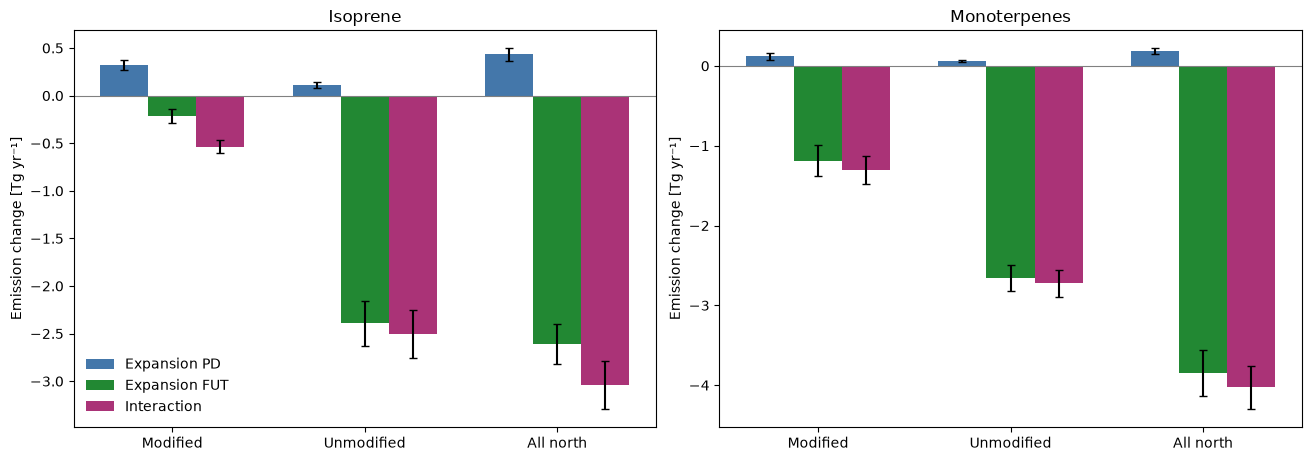

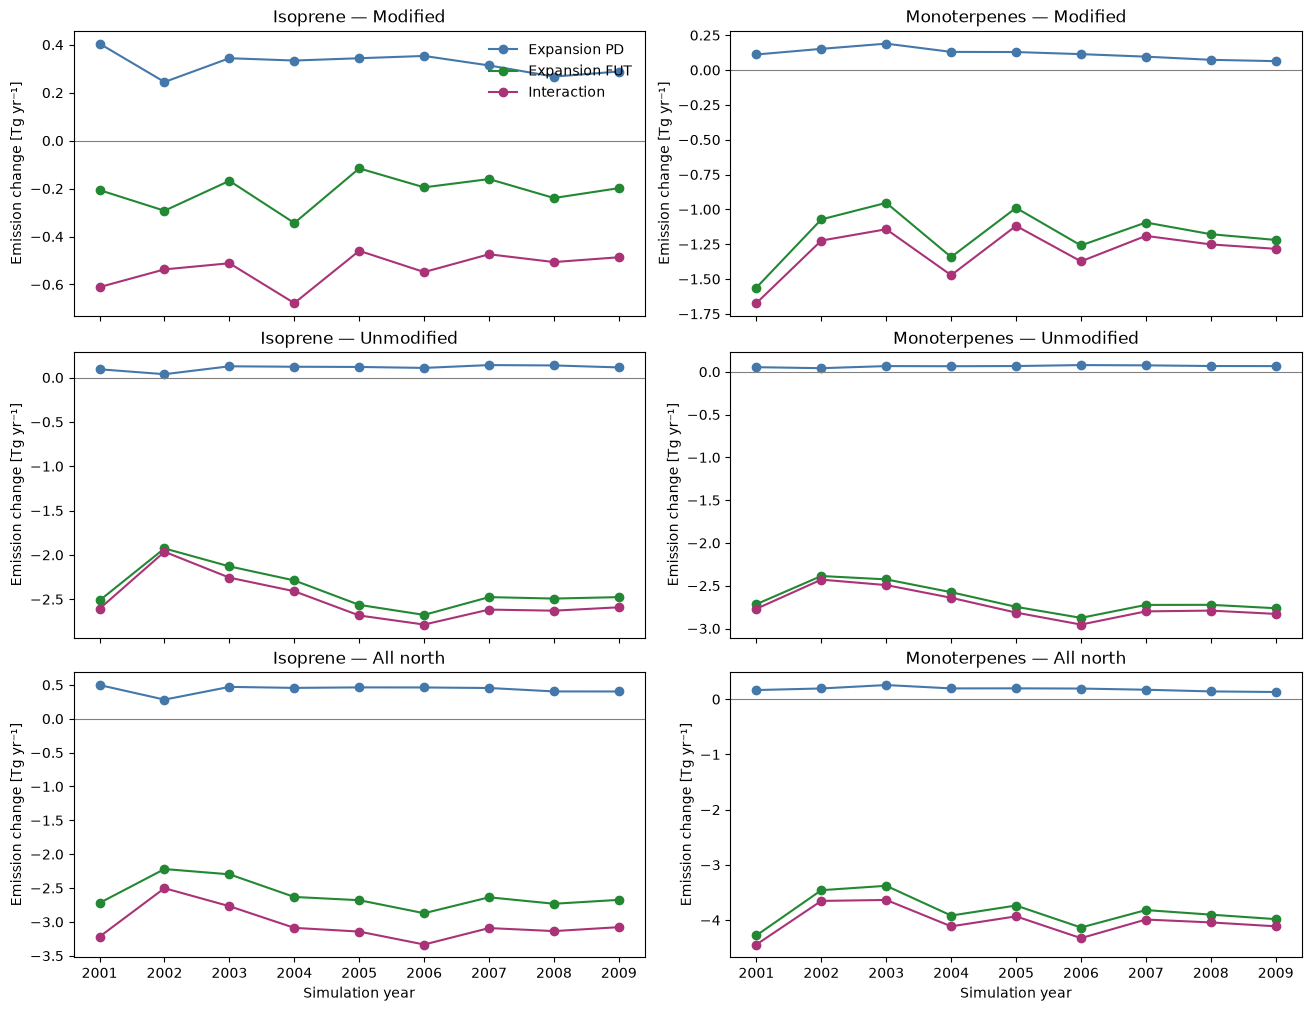

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
x, width = np.arange(len(REGIONS)), .25
for ax, var in zip(axes, VARS):
    for i, effect in enumerate(EFFECTS):
        y = annual[var].sel(effect=effect, region=REGIONS)
        ax.bar(x + (i - 1) * width, y.mean("year"), width, yerr=y.std("year", ddof=1),
               capsize=3, color=EFFECT_COLORS[effect], label=effect)
    ax.axhline(0, color="0.5", linewidth=.8)
    ax.set(title=LABELS[var], xticks=x, xticklabels=REGIONS, ylabel="Emission change [Tg yr⁻¹]")
axes[0].legend(frameon=False)
fig.savefig(OUT / "regional_expansion_interaction.png", dpi=200)
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for effect in EFFECTS:
            y = annual[var].sel(region=region, effect=effect)
            ax.plot(y.year, y, "o-", label=effect, color=EFFECT_COLORS[effect])
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
        if i == 2:
            ax.set_xlabel("Simulation year")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "annual_expansion_interaction.png", dpi=200)
plt.show()

## 6. Seasonal comparison
Mean fluxes use each region's own area denominator. Y-scales are shared across regions for each species. These curves can expose seasonal sign reversals hidden in annual totals.

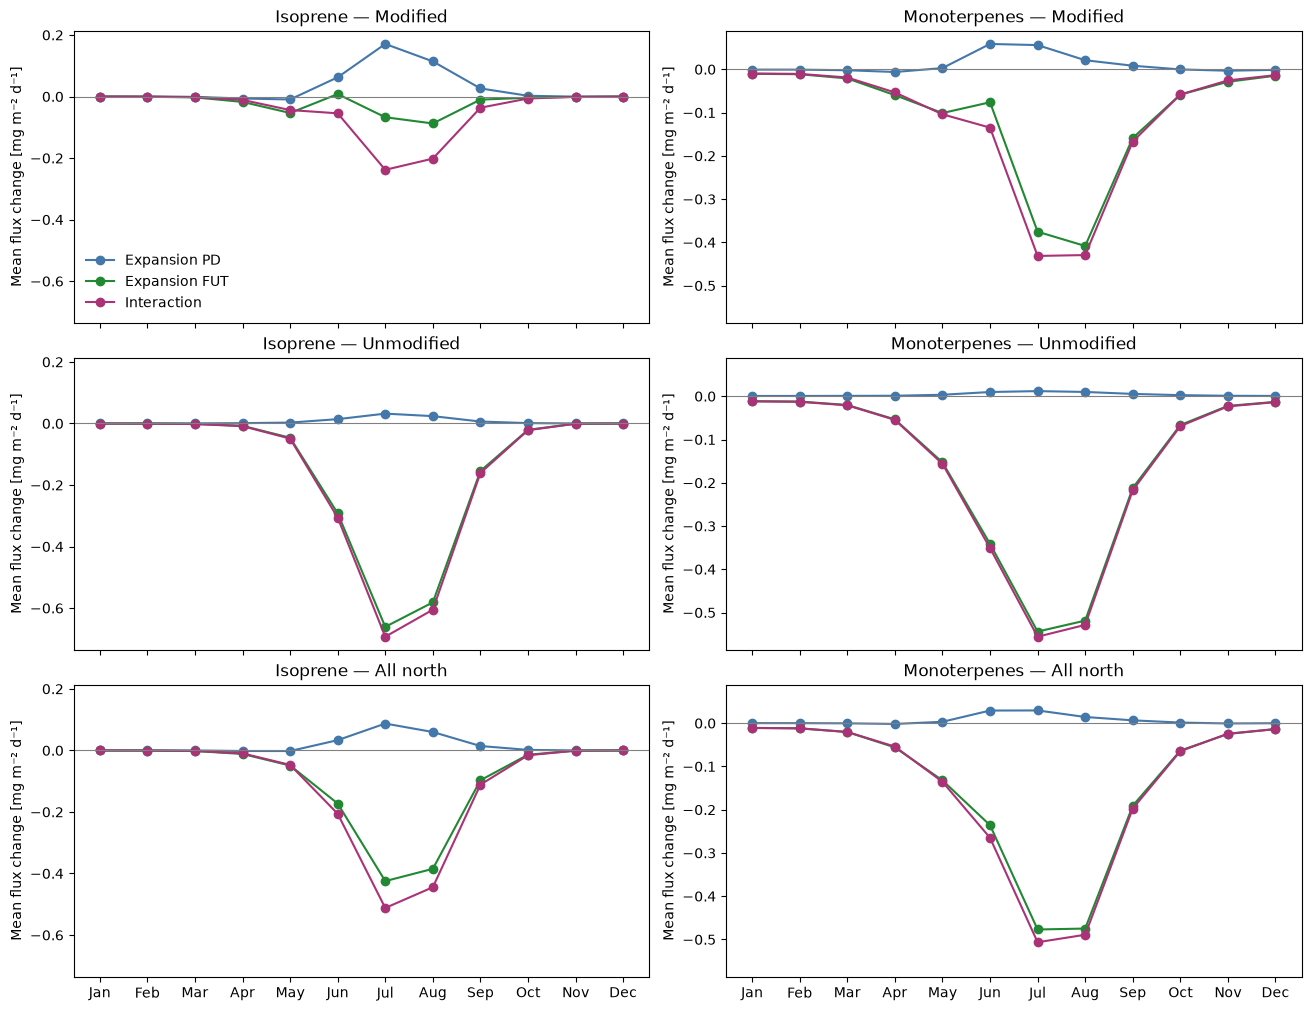

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True, sharey="col", constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        for effect in EFFECTS:
            y = seasonal[var].sel(region=region, effect=effect)
            ax.plot(y.month, y, "o-", label=effect, color=EFFECT_COLORS[effect])
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Mean flux change [mg m⁻² d⁻¹]",
               xticks=range(1, 13), xticklabels=list(calendar.month_abbr)[1:])
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "seasonal_expansion_interaction.png", dpi=200)
plt.show()

## 7. Spatial cancellation
Separate positive and negative **annual-mean grid-cell** contributions. Their sum is the net budget. A small regional interaction can conceal strong opposing local interactions; this does not measure cancellation between seasons within each cell.

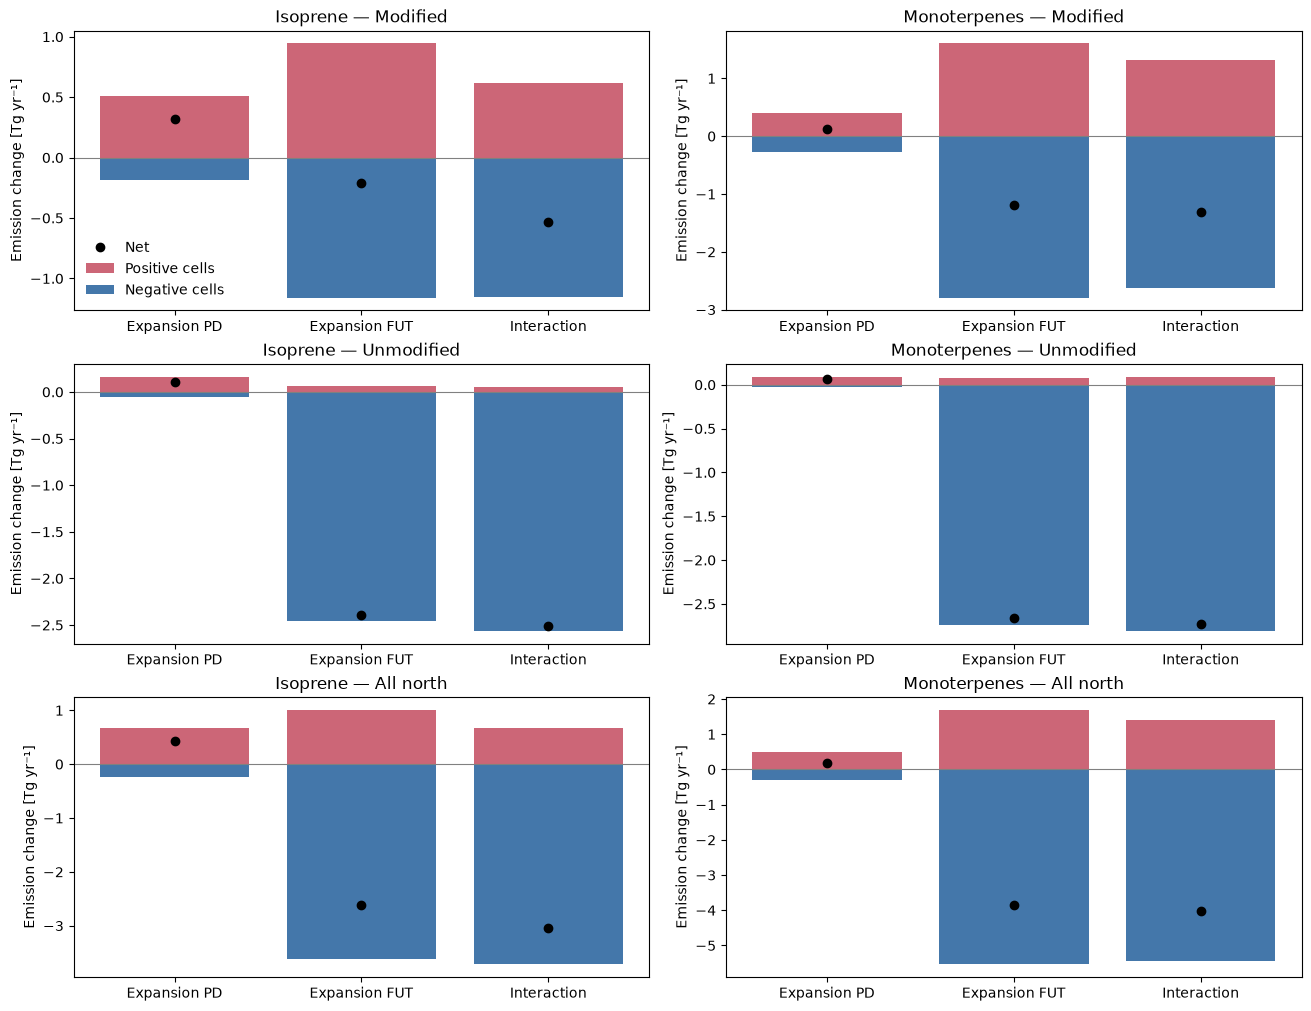

In [8]:
cell_mean = annual_cell_mass.mean("year")
positive = (cell_mean.clip(min=0) * region_weights).sum(("lat", "lon"))
negative = (cell_mean.clip(max=0) * region_weights).sum(("lat", "lon"))
net = annual.mean("year")
xr.testing.assert_allclose(positive + negative, net)
cancellation = xr.concat([positive, negative, net], pd.Index(["Positive", "Negative", "Net"], name="component"))
cancellation.to_dataframe().to_csv(OUT / "spatial_cancellation.csv")

fig, axes = plt.subplots(3, 2, figsize=(13, 10), constrained_layout=True)
for i, region in enumerate(REGIONS):
    for j, var in enumerate(VARS):
        ax = axes[i, j]
        ax.bar(EFFECTS, positive[var].sel(region=region), color="#CC6677", label="Positive cells")
        ax.bar(EFFECTS, negative[var].sel(region=region), color="#4477AA", label="Negative cells")
        ax.plot(EFFECTS, net[var].sel(region=region), "ko", label="Net")
        ax.axhline(0, color="0.5", linewidth=.8)
        ax.set(title=f"{LABELS[var]} — {region}", ylabel="Emission change [Tg yr⁻¹]")
axes[0, 0].legend(frameon=False)
fig.savefig(OUT / "spatial_cancellation.png", dpi=200)
plt.show()

## 8. Compare the two attribution sequences
Sequence A changes the background first, then expands vegetation.
Sequence B expands vegetation first, then changes the background.

Both sum to LCC_FUT − CTRL_PD. Their different expansion terms reflect the interaction. This check quantifies how much the emissions attribution depends on the intermediate reference; it does not measure the corresponding cloud or radiative responses.

In [9]:
path_terms = {
    "Background with control vegetation": background_ctrl,
    "Expansion in FUT": effects["Expansion FUT"],
    "Expansion in PD": effects["Expansion PD"],
    "Background with expanded vegetation": background_lcc,
}
path_flux = xr.concat(list(path_terms.values()), pd.Index(list(path_terms), name="term"))
path_annual = ((path_flux * region_weights).sum(("lat", "lon")) * seconds / 1e9).groupby("year").sum("time")
xr.testing.assert_allclose(path_annual.isel(term=0, drop=True) + path_annual.isel(term=1, drop=True),
                           path_annual.isel(term=2, drop=True) + path_annual.isel(term=3, drop=True))
path_annual.mean("year").to_dataframe().to_csv(OUT / "attribution_sequences_mean_Tg_yr.csv")
display(path_annual.mean("year").to_dataframe().round(4))

SFISOP  SFMTERP
term                                region                      
Background with control vegetation  Modified     7.7100  16.5127
                                    Unmodified   5.2845   8.9397
                                    All north   12.9945  25.4523
Expansion in FUT                    Modified    -0.2131  -1.1856
                                    Unmodified  -2.3936  -2.6594
                                    All north   -2.6067  -3.8450
Expansion in PD                     Modified     0.3215   0.1177
                                    Unmodified   0.1112   0.0648
                                    All north    0.4327   0.1825
Background with expanded vegetation Modified     7.1755  15.2094
                                    Unmodified   2.7797   6.2155
                                    All north    9.9551  21.4249

## 9. Annual and JJA maps
Optional Cartopy maps: rows are species; columns are Expansion PD, Expansion FUT and Interaction. Colour scales are symmetric. With `SCALE_MODE = "grouped"` (default) Expansion PD has its own scale, because it is ~10× weaker than the FUT effect; Expansion FUT and Interaction share one scale so they stay comparable. **Compare PD with FUT through the colourbar values, not the colours.** `SCALE_QUANTILE = 0.98` clips the 2 % most extreme cells (colourbar extensions); 1.0 uses the full range. The map is not a significance map.

The same mask is used for all comparisons. Green outlines identify the modified footprint. The JJA map uses only June–August and weights months by duration.

In [10]:
from matplotlib.colors import ListedColormap, Normalize

# Blue and red scales with no white or near-white centre.
n = 256
cmap_nonzero = ListedColormap(np.vstack([
    plt.get_cmap("PuBuGn")(np.linspace(1.0, 0, n)),
    plt.get_cmap("YlOrRd")(np.linspace(0, 1.0, n)),
]))
cmap_nonzero.set_bad("#d9d9d9")  # Missing data remain distinguishable from zero.


class ExactZeroWhite(ListedColormap):
    def __call__(self, X, alpha=None, bytes=False):
        rgba = super().__call__(X, alpha=alpha, bytes=bytes)
        values = np.ma.asarray(X)
        zero = (np.ma.getdata(values) == 0.5) & ~np.ma.getmaskarray(values)

        if np.ndim(X) == 0:
            return ((255, 255, 255, rgba[3]) if bytes else (1., 1., 1., rgba[3])) if zero else rgba

        rgba[..., :3] = np.where(np.asarray(zero)[..., None], 255 if bytes else 1., rgba[..., :3])
        return rgba


cmap = ExactZeroWhite(cmap_nonzero.colors, name="blue_zero_white_red")
cmap.set_bad("#d9d9d9")

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

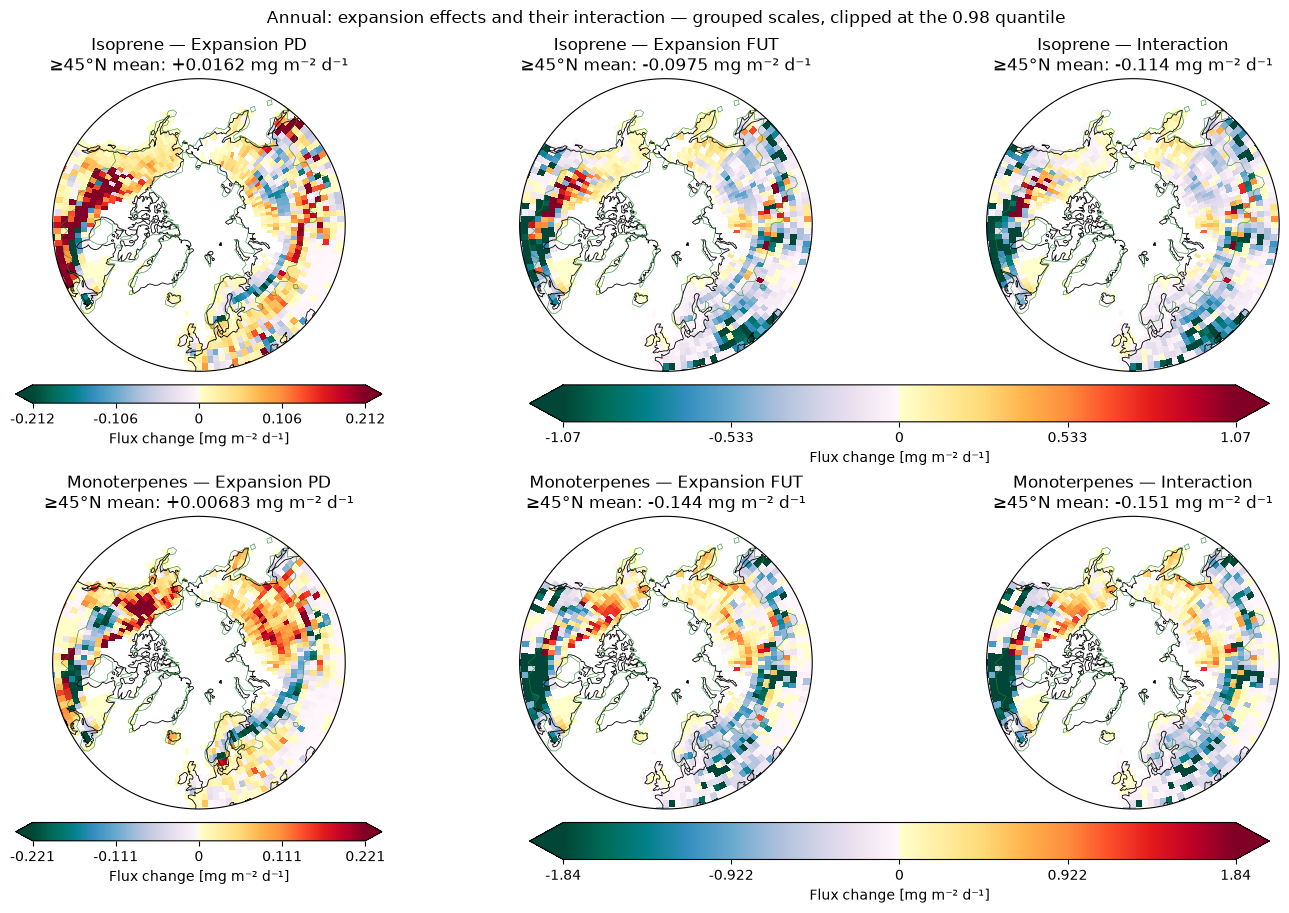

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

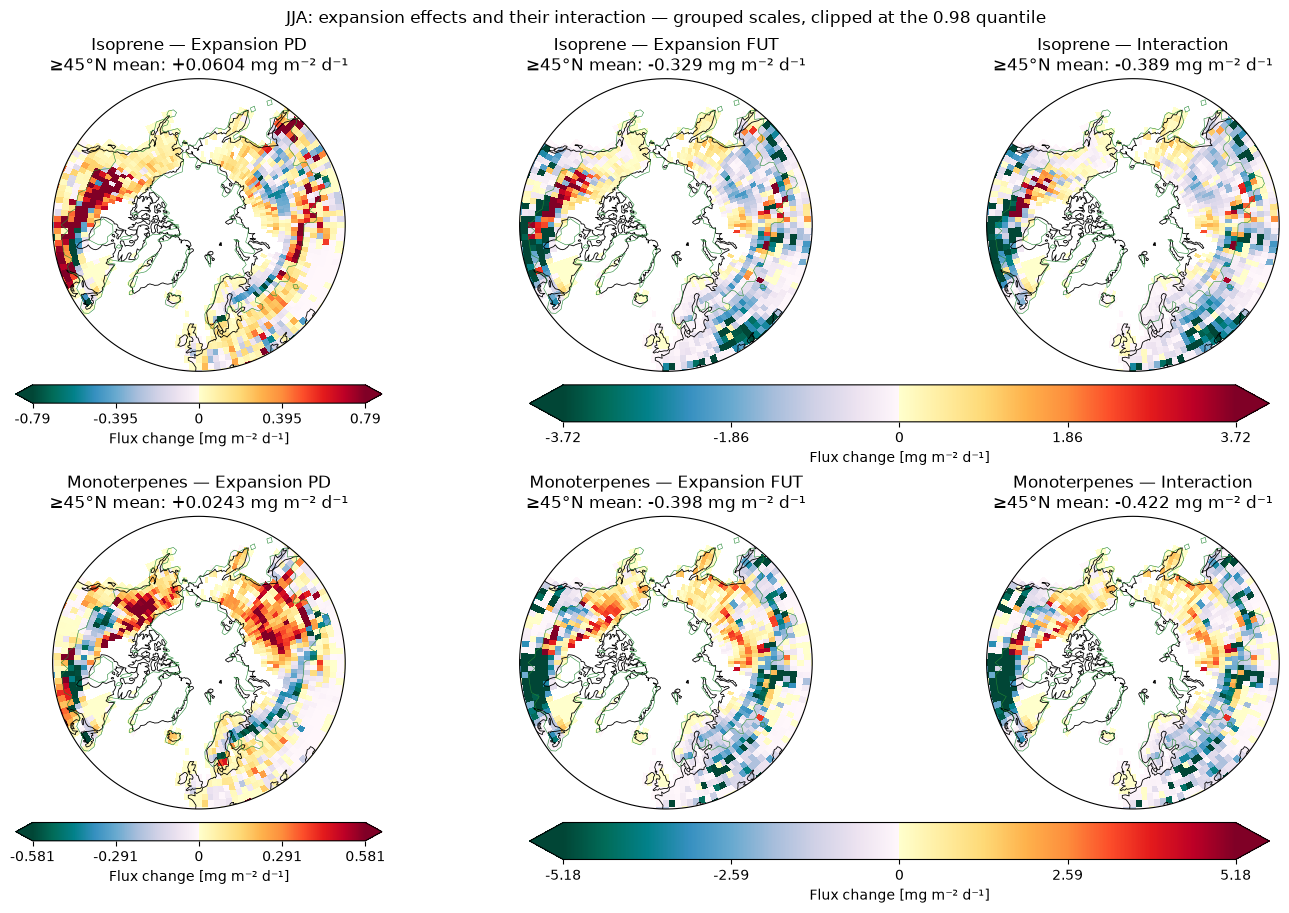

In [11]:
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FormatStrFormatter

# "grouped": PD on its own scale, FUT and Interaction share one (PD is ~10x weaker);
# "shared": one scale per row; "individual": one scale per panel
SCALE_MODE = "grouped"
SCALE_QUANTILE = 0.98  # 1.0 = full range; a few extreme cells otherwise wash out the maps
SCALE_GROUPS = {"grouped": [["Expansion PD"], ["Expansion FUT", "Interaction"]],
                "shared": [EFFECTS], "individual": [[e] for e in EFFECTS]}[SCALE_MODE]
"""
# Continuous blue–white–red, with no finite-width white bin.
base = plt.get_cmap("RdBu_r")
cmap = LinearSegmentedColormap.from_list(
    "continuous_bwr",
    [(0, base(0)), (.25, base(.25)), (.5, "white"), (.75, base(.75)), (1, base(1))],
    N=1025,
)
"""
theta = np.linspace(0, 2 * np.pi, 200)
circle = MplPath(np.column_stack([np.sin(theta), np.cos(theta)]) * .5 + .5)
jja = reference.month.isin([6, 7, 8])
jja_maps = (flux * seconds).where(jja).sum("time") / seconds.where(jja).sum() * 86400 * 1e6
w = region_weights.sel(region="All north", drop=True)

mask_cyclic, _ = add_cyclic_point(modified.transpose("lat", "lon").values.astype(float),
                                  coord=reference.lon.values)

for season, mapped in [("Annual", maps), ("JJA", jja_maps)]:
    fig, axes = plt.subplots(2, 3, figsize=(14, 9),
                             subplot_kw={"projection": ccrs.NorthPolarStereo()}, constrained_layout=True)

    for row, var in enumerate(VARS):
        for group in SCALE_GROUPS:
            values = np.abs(mapped[var].sel(effect=group).where(north).values)
            limit = max(float(np.nanquantile(values, SCALE_QUANTILE)), 1e-12)
            group_axes = [axes[row, EFFECTS.index(effect)] for effect in group]

            for ax, effect in zip(group_axes, group):
                field = mapped[var].sel(effect=effect).transpose("lat", "lon")
                cyclic, longitude = add_cyclic_point(field.values, coord=field.lon.values)
                mesh = ax.pcolormesh(longitude, field.lat, cyclic, transform=ccrs.PlateCarree(),
                                     cmap=cmap, norm=Normalize(vmin=-limit, vmax=limit), shading="auto")
                ax.contour(longitude, field.lat, mask_cyclic, levels=[.5], colors=["#228833"],
                           linewidths=.4, transform=ccrs.PlateCarree())
                ax.set_extent([-180, 180, MIN_LAT, 90], crs=ccrs.PlateCarree())
                ax.set_boundary(circle, transform=ax.transAxes)
                ax.coastlines(linewidth=.6)
                avg = float((field * w).sum() / w.sum())
                ax.set_title(f"{LABELS[var]} — {effect}\n≥{MIN_LAT}°N mean: {avg:+.3g} mg m⁻² d⁻¹")

            fig.colorbar(mesh, ax=group_axes, orientation="horizontal", shrink=.8, pad=.04,
                         extend="both", ticks=np.linspace(-limit, limit, 5),
                         format=FormatStrFormatter("%.3g"), label="Flux change [mg m⁻² d⁻¹]")

    fig.suptitle(f"{season}: expansion effects and their interaction — {SCALE_MODE} scales, clipped at the {SCALE_QUANTILE:g} quantile")
    fig.savefig(OUT / f"{season.lower()}_interaction_continuous_{SCALE_MODE}.png", dpi=200)
    plt.show()

## Interpretation checklist

- **Interaction ≈ 0:** the net expansion effect is similar in PD and FUT. Check maps and seasons for cancellation before concluding weak dependence everywhere.
- **Interaction > 0:** expansion increases emissions more, or reduces them less, in FUT.
- **Interaction < 0:** expansion reduces emissions more, or increases them less, in FUT.
- **PD and FUT effects with opposite signs:** a reversal of the net expansion-associated response.
- **Interaction concentrated outside modified cells:** investigate environmental responses and verify that the mask covers all intended imposed changes.
- **Large regional or local interaction:** strengthens the motivation for examining both attribution sequences. It does not, by itself, determine whether an additional fixed-LCC_PD atmospheric simulation is necessary.
- **Small emissions interaction:** does not imply a small atmospheric sensitivity difference; chemistry, aerosols and clouds can respond differently in PD and FUT.
- A global check may be useful later: this notebook's regional results are limited to ≥45°N.
- ISOP/MTERP only: no conclusions about other BVOC species are implied.

All CSVs and figures are saved in OUT. The notebook contains no computed scientific conclusions until run on the four simulation datasets.

## Results (2001–2009, ≥45°N, Tg yr⁻¹, mean ± interannual SD)

| Region | Species | Expansion PD | Expansion FUT | Interaction |
|---|---|---:|---:|---:|
| Modified | Isoprene | +0.32 ± 0.05 | −0.21 ± 0.07 | −0.53 ± 0.07 |
| Modified | Monoterpenes | +0.12 ± 0.04 | −1.19 ± 0.19 | −1.30 ± 0.18 |
| Unmodified | Isoprene | +0.11 ± 0.03 | −2.39 ± 0.24 | −2.50 ± 0.25 |
| Unmodified | Monoterpenes | +0.06 ± 0.01 | −2.66 ± 0.16 | −2.72 ± 0.17 |
| All north | Isoprene | +0.43 ± 0.06 | −2.61 ± 0.21 | −3.04 ± 0.25 |
| All north | Monoterpenes | +0.18 ± 0.04 | −3.85 ± 0.29 | −4.03 ± 0.27 |

- **The sign reverses:** expansion slightly *increases* emissions in PD (positive in all 9 years), but *decreases* them in FUT (negative in all 9 years). The interaction is therefore almost the whole FUT expansion effect.
- **Most of the FUT decrease is outside the modified cells** (isoprene 92 %, monoterpenes 69 % of the northern total), where vegetation is unchanged. This points to a vegetation-induced environmental response (e.g. temperature/radiation) in the future background, not to a change in emission capacity. That is inference; the mechanism diagnostics (in `bvoc_emissions_decomposition.ipynb`, section 14) have not been run yet.
- **Attribution depends on the path:** with control vegetation the background adds +12.99 / +25.45 Tg yr⁻¹ (isoprene / monoterpenes); with expanded vegetation it adds +9.96 / +21.42 Tg yr⁻¹.
- **Maps (§9):** PD has its own colour scale, ~5× narrower than FUT/Interaction (annual isoprene ±0.21 vs ±1.07 mg m⁻² d⁻¹, 98th percentile). In PD, positive changes dominate over western Canada, Alaska and eastern Siberia, with negative bands near the southern edge of the modified area. Compare magnitudes using the colourbars.

Outputs: `bvoc_expansion_PD_FUT_interaction_outputs/` (`expansion_interaction_summary.csv`, `attribution_sequences_mean_Tg_yr.csv`, figures).